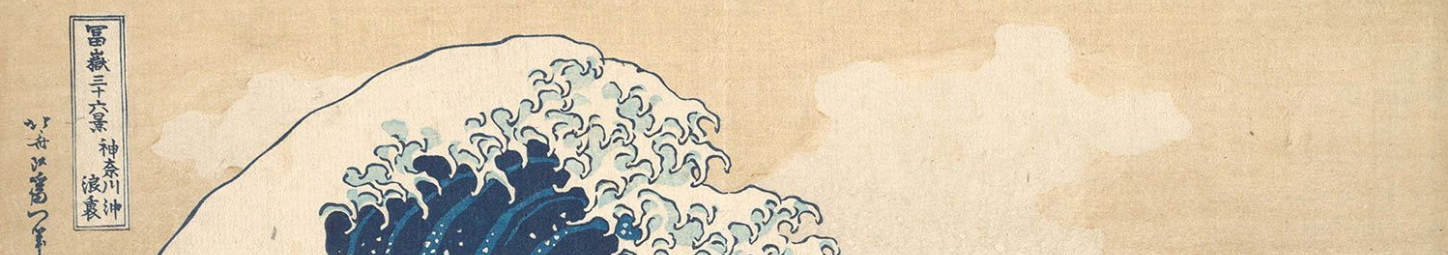

<center><table><tr><font  size=6>K近邻——用户观影推荐</font></tr></table></center>

# 🌊 情景导入

&emsp;&emsp;<font  size=3>在爱奇艺上，我们有一系列电影的类型（如动作片，爱情片，喜剧片）和镜头的统计数据（打斗、拥抱、亲吻等镜头），唐人街探案是最近新上的一部电影，同事小派统计了唐人街探案的镜头数并进行了划分，那么我们在已知这些电影镜头数的情况下，有没有什么方法能够很方便地去划分这个电影的类型？比如说根据用户的观影习惯去做一套推荐系统呢？
假设现在有这样的九部电影，我们有前8部电影的不同类型的镜头数和对应的电影类型数据，最后一部《唐人街探案》电影只有镜头数据，能否根据前8部电影去预测《唐人街探案》的电影类型呢？</font>

# 🌈 实训目标

><font  size=3.5>使用机器学习中K近邻（KNN）算法进行电影类型的分类</font>


# 📘 实训要点

><font  size=3.5>1. 理解K近邻的算法思想</font>

><font  size=3.5>2. 理解欧式距离的含义</font>

## ☞  K近邻

<font  size=3.5>K近邻是机器学习算法中经典的算法，它既可以用来做分类，也可以用来做回归。本案例只探究KNN用来做分类。</font>

☞☞ **算法思想**

&emsp;&emsp;<font  size=3.5>KNN近邻算法实际上是利用样本之间的相似性来进行分类，简单来说和```人以类聚，物以群分```是一个道理，也可以说```近朱者赤近墨者黑```。比如小派和朋友小周一起去看电影，以下是你们对电影分类的讨论。</font>

><font  size=3>小派🙍：刚刚的电影很精彩，打斗场景非常真实，又是一部优秀的动作片！</font>

><font  size=3>小周🙍‍♂：是吗？我怎么感觉这是一部爱情片呢？真心被男主女主的爱情感动了，唔。。。</font>

><font  size=3>小派🙍：是动作片好不好？不信的话我们用K近邻来分类！</font>

><font  size=3>小周🙍‍♂：K近邻是什么，怎么分类？</font>

><font  size=3>小派🙍：我们以接吻镜头与打斗镜头作为两种电影的特征，只要知道一部电影的接吻镜头与打斗镜头的个数，利用现有的带标签数据集便可以对未知类型的电影进行类型预测。</font>

><font  size=3>小周🙍‍♂： 不是很明白，可以讲简单点吗？</font>

><font  size=3>小派🙍：我们可以这样理解，假设有一个未知的x，我们尽量让特征相近的的点靠近，这样想要知道x是什么性质的，我们可以观察它邻近的k个点，这些点多数是什么性质的，那么x的性质也就是可以预测出来了。</font>

><font  size=3>小周🙍‍♂： 哦哦，明白了。有点像那句俗语——物以类聚人以群分呢！</font>


☞☞ **欧氏距离** 

&emsp;&emsp;<font  size=3.5>在介绍k近邻算法之前，我们先了解它的一个核心理念——欧几里得距离，欧几里得距离就是连接两点之间的一条直线。</font>

<br><center>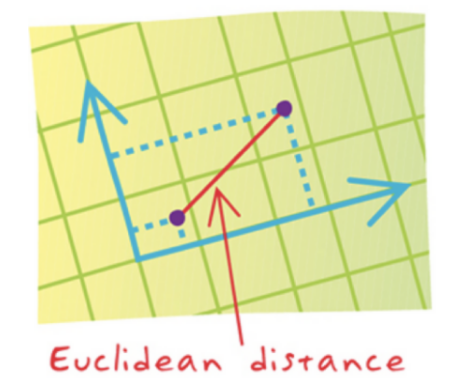</center>



☞☞ **KNN适用场景**

><font size=3.5> 保险行业、金融行业、零售业———用户推荐系统
    
><font size=3.5> 当需要一个特别容易解释的模型，且需要定期维护、实时更新的项目任务

# ⏰ 实训步骤

 ## ✏️ 步骤1 导入相关包
&emsp;&emsp;<font  size=3.5>第一步先导入相关的库，在本案例中，我们需要从```sklearn```中的```neighbors```模块中导入KNN方法。</font>

👉 **示例代码**
```python 

from sklearn.neighbors import KNeighborsClassifier#导入KNN分类器
import numpy as np#导入科学计算库
``` 

👇 **动手练习，导入相关包**

In [1]:
#导入必要的包

from sklearn.neighbors import KNeighborsClassifier#导入KNN分类器
import numpy as np#导入科学计算库



## ✏️ 步骤2 获取数据
&emsp;&emsp;<font  size=3.5>接下来建立一个数据集，如下列代码所示group为数据集，labels为数据集对应的分类标签，其中，group数据集中每个样本有三个特征，第一列搞笑镜头，第二列为打斗镜头，第三列为亲吻镜头数；labels里面也是一个数据的分类标签，分别是爱情片、喜剧片、动作片。</font>

👉 **示例代码**
```python 

x_train = np.array([[1,23,101],[5,23,89],[11,108,5],[115,16,8]])#数据的二维特征，共四组，这些作为训练集特征
  
y_train = ['爱情片','爱情片','动作片','喜剧片']  #数据的标签，也四组。这些作为训练集标签

``` 

👇 **动手练习，获取数据**

In [2]:
#获取数据


x_train = np.array([[1,23,101],[5,23,89],[11,108,5],[115,16,8]])#数据的二维特征，共四组

y_train = ['爱情片','爱情片','动作片','喜剧片']  #数据的标签，也四组




## ✏️ 步骤3 实例化一个分类器
&emsp;&emsp;<font  size=3.5>在```sklearn```中，估计器是一个重要的角色，分类器和回归器都属于估计器。KNN中用到的估计器为```KNeighborsClassifier```。</font>

**KNeighborsClassifier函数参数的说明**
```python
class sklearn.neighbors.KNeighborsClassifier(n_neighbors, weights=’uniform’,algorithm=’auto’, leaf_size=30, p=2, metric=’minkowski’, metric_params=None, n_jobs=None)
```
><font size=3.5 >```n_neighbors```：</font><font  size=3.5> 就是K值，K个最近的邻居，默认为5。</font>

><font size=3.5 >```weights```：</font><font  size=3.5>  默认是uniform，参数可以是uniform、distance，也可以是用户自己定义的函数。uniform是均等的权重，就说所有的邻近点的权重都是相等的。</font>

><font size=3.5 >```algorithm```：</font><font  size=3.5> 可选参数，默认是uniform，参数可以是uniform、distance，也可以是用户自己定义的函数。uniform是均等的权重，就说所有的邻近点的权重都是相等的。</font>

><font size=3.5 >```metric```：</font><font  size=3.5>  默认为’minkowski’用于距离度量，默认度量是minkowski，也就是p=2的欧氏距离(欧几里德度量)。</font>

><font size=3.5 >```leaf_size```：</font><font  size=3.5> 可选参数， 默认是30，这个是构造的kd树和ball树的大小。这个值的设置会影响树构建的速度和搜索速度，同样也影响着存储树所需的内存大小。需要根据问题的性质选择最优的大小。</font>

><font size=3.5 >```p```：</font><font  size=3.5>  距离度量公式。这个参数默认为2，也就是默认使用欧式距离公式进行距离度量。也可以设置为1，使用曼哈顿距离公式进行距离度量。</font>

👉 **示例代码**
```python 

knn=KNeighborsClassifier(n_neighbors=3)#实例化一个KNN分类器，设置KNN中的K为3
```

👇 **动手练习，创建一个KNN估计器**

In [9]:
# 请输入代码


knn=KNeighborsClassifier(n_neighbors=3)#实例化一个KNN分类器，设置KNN中的K为3

## ✏️ 步骤4 调用fit方法,进行模型训练

**KNeighborsClassifier中fit(X, y)方法的说明**

><font size=3.5 >```fit(X, y)```：</font><font  size=3.5> 使用X作为训练数据，y作为目标值（类似于标签）来拟合模型。</font>

👉 **示例代码**
```python 

knn.fit(x_train,y_train)#传入训练集数据和标签进行训练
```

👇 **动手练习，调用fit方法**

In [10]:
# 请输入代码

knn.fit(x_train,y_train)#传入训练集数据和标签进行训练


KNeighborsClassifier(n_neighbors=2)

## ✏️ 步骤5 对训练好的估计器进行预测

**KNeighborsClassifier方法的说明**

><font  size=3.5>```predict(self, X)```：</font><font  size=3.5>预测X中样本的标签。参数X : 就是测试样本。返回的是一个列表，是每个样本的预测值构成的。</font>

<details>
  <summary><font size=3.5 >点击查看KNeighborsClassifier的其他方法</font></summary>
    
><font size=3.5 >```predict(X)：```：</font><font  size=3.5>给提供的数据预测对应的标签。</font>

><font size=3.5 >```predict_proba(X)```：</font><font  size=3.5>返回X数据集中对应每个标签的概率估计值。</font>

><font size=3.5 >```score(X, y[, sample_weight])```：</font><font  size=3.5>返回给定测试数据和标签上的平均准确度</font>

><font size=3.5 >```set_params(**params)```：</font><font  size=3.5>设置此估算器的参数</font></details>

👉 **示例代码**
```python 

test = [[101,30,20]]
    #kNN分类
test_class = knn.predict(test)#传入测试集的数据进行预测
    #打印分类结果
print(test_class)#打印出测试集的类别
```

👇**动手练习，对测试集进行预测**

In [11]:
# 请输入代码


test = [[101,30,20]]
    #kNN分类
test_class = knn.predict(test)#传入测试集的数据进行预测
    #打印分类结果
print(test_class)#打印出测试集的类别



['喜剧片']


## ✏️ 步骤6 可视化展示
<font  size=3.5>下面来进行可视化展示，在下面的面板中填入相关的镜头数，再点击```Run Interact```按钮对新电影进行分类</font>

👉 **示例代码**
```python 
import warnings#导入警告
warnings.filterwarnings("ignore")#在出现警告的时候，忽略警告

import ipywidgets as wg#导入交互式控件
@wg.interact_manual()

def doing_actions(搞笑镜头='',打斗镜头='',亲吻镜头=''):
    newmovie = np.array([[搞笑镜头,打斗镜头,亲吻镜头]])#输入数据转为numpy矩阵
    
    y_movie=knn.predict(newmovie)
    print('新电影的搞笑镜头数为:',搞笑镜头,'，打斗镜头数为:',打斗镜头,'，亲吻镜头数为:',亲吻镜头,'，该电影的类型被预测为：',y_movie)
   
```

👇**动手练习，填入相关参数**

In [16]:
## import warnings#导入警告
warnings.filterwarnings("ignore")#在出现警告的时候，忽略警告

import ipywidgets as wg#导入交互式控件
@wg.interact_manual()

def doing_actions(搞笑镜头='',打斗镜头='',亲吻镜头=''):
    newmovie = np.array([[搞笑镜头,打斗镜头,亲吻镜头]])#输入数据转为numpy矩阵
    
    y_movie=knn.predict(newmovie)
    print('新电影的搞笑镜头数为:',搞笑镜头,'，打斗镜头数为:',打斗镜头,'，亲吻镜头数为:',亲吻镜头,'，该电影的类型被预测为：',y_movie)
   

interactive(children=(Text(value='', description='搞笑镜头'), Text(value='', description='打斗镜头'), Text(value='', d…

# 🉐 实训心得

&emsp;&emsp;<font  size=3.5>在学习完K近邻算法之后，相信大家都对K近邻有了自己的理解和认知；<font color="#0000ff" size=3>在实训步骤的第五步，我们可以选择其他的K值，看看K值的不同对预测结果有什么变化吧！</font>请结合职业教育教法的特点，将你自己对该算法的认识、教学案例的设计等任何感想写在下面的cell里面。</font>

👇 **动手练习，写下你的实训总结**

In [15]:
#请勿运行，直接填写






👇 **点击下面 💬 有惊喜**

<font  size=3.5>恭喜你学会K近邻算法，下面请领取你的奖励：</font>

💯💯💯👍👍👍🥇🥇🥇🍰🍰🍰🎮🎮🎮😊😊😊